In [1]:
from pathlib import Path
import json
import gzip
import csv
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path(r"D:\PixoAnalytics\Image Retrieval Project")

IMAGE_DIR = ROOT / "images" / "small"
LISTING_DIR = ROOT / "listings" / "metadata"

print("Images:", IMAGE_DIR)
print("Listings:", LISTING_DIR)

Images: D:\PixoAnalytics\Image Retrieval Project\images\small
Listings: D:\PixoAnalytics\Image Retrieval Project\listings\metadata


In [2]:
listing_file = LISTING_DIR / "listings_0.json"

records = []

with open(listing_file, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        if line:
            records.append(json.loads(line))

print("Number of records:", len(records))

# Inspect the first record
records[0]

Number of records: 9232


{'brand': [{'language_tag': 'nl_NL', 'value': 'find.'}],
 'bullet_point': [{'language_tag': 'nl_NL', 'value': 'Schoen in Loafer-stijl'},
  {'language_tag': 'nl_NL', 'value': 'Platform hak'},
  {'language_tag': 'nl_NL', 'value': 'Cap teen'},
  {'language_tag': 'nl_NL', 'value': 'Middenhak'}],
 'color': [{'language_tag': 'nl_NL', 'value': 'Veelkleurig Vrouw Blauw'}],
 'item_id': 'B06X9STHNG',
 'item_name': [{'language_tag': 'nl_NL',
   'value': 'Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK'}],
 'model_name': [{'language_tag': 'nl_NL', 'value': '37753'}],
 'model_number': [{'value': '12-05-04'}],
 'model_year': [{'value': 2017}],
 'product_type': [{'value': 'SHOES'}],
 'style': [{'language_tag': 'nl_NL', 'value': 'Gesloten-teen pompen'}],
 'main_image_id': '81iZlv3bjpL',
 'other_image_id': ['91mIRxgziUL', '91eqBkW06wL', 'A1BHZSKNbkL'],
 'item_keywords': [{'language_tag': 'nl_NL', 'value': 'block heel shoes'},
  {'language_tag': 'nl_NL', 'value': 'loa

In [3]:
first_record = records[0]

print("Available fields:\n")

for key, value in first_record.items():
    print(f"{key}: {type(value).__name__}")

    if isinstance(value, (str, int, float)):
        print("   ", str(value)[:200])
    elif isinstance(value, list):
        print("   ", value[:3])
    elif isinstance(value, dict):
        print("   ", list(value.keys())[:15])

Available fields:

brand: list
    [{'language_tag': 'nl_NL', 'value': 'find.'}]
bullet_point: list
    [{'language_tag': 'nl_NL', 'value': 'Schoen in Loafer-stijl'}, {'language_tag': 'nl_NL', 'value': 'Platform hak'}, {'language_tag': 'nl_NL', 'value': 'Cap teen'}]
color: list
    [{'language_tag': 'nl_NL', 'value': 'Veelkleurig Vrouw Blauw'}]
item_id: str
    B06X9STHNG
item_name: list
    [{'language_tag': 'nl_NL', 'value': 'Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK'}]
model_name: list
    [{'language_tag': 'nl_NL', 'value': '37753'}]
model_number: list
    [{'value': '12-05-04'}]
model_year: list
    [{'value': 2017}]
product_type: list
    [{'value': 'SHOES'}]
style: list
    [{'language_tag': 'nl_NL', 'value': 'Gesloten-teen pompen'}]
main_image_id: str
    81iZlv3bjpL
other_image_id: list
    ['91mIRxgziUL', '91eqBkW06wL', 'A1BHZSKNbkL']
item_keywords: list
    [{'language_tag': 'nl_NL', 'value': 'block heel shoes'}, {'language_tag': 'nl

In [5]:
image_csv = IMAGE_DIR / "images.csv.gz"

with gzip.open(image_csv, "rt", encoding="utf-8") as f:
    image_df = pd.read_csv(f)

print("Shape:", image_df.shape)
print("\nColumns:")
print(image_df.columns.tolist())

display(image_df.head())

Shape: (398212, 4)

Columns:
['image_id', 'height', 'width', 'path']


,image_id,height,width,path
0,010-mllS7JL,106,106,14/14fe8812.jpg
1,01dkn0Gyx0L,122,122,da/daab0cad.jpg
2,01sUPg0387L,111,111,d2/d2daaae9.jpg
3,1168jc-5r1L,186,186,3a/3a4e88e6.jpg
4,11RUV5Fs65L,30,500,d9/d91ab9cf.jpg


In [6]:
import json
import pandas as pd

listing_files = sorted(LISTING_DIR.glob("listings_*.json"))

print(f"Found {len(listing_files)} listing files")

product_rows = []
product_image_rows = []

def extract_value(field):
    """Extract the first available value from ABO's multilingual metadata fields."""
    if not field:
        return None

    if isinstance(field, str):
        return field

    if isinstance(field, list):
        for entry in field:
            if isinstance(entry, dict) and entry.get("value") is not None:
                return entry["value"]

    return None


for file_path in listing_files:

    print(f"Processing {file_path.name}...")

    with open(file_path, "r", encoding="utf-8") as f:

        for line in f:

            if not line.strip():
                continue

            product = json.loads(line)

            product_id = product.get("item_id")

            if not product_id:
                continue

            # Keep useful product metadata
            product_rows.append({
                "product_id": product_id,
                "title": extract_value(product.get("item_name")),
                "brand": extract_value(product.get("brand")),
                "product_type": extract_value(product.get("product_type")),
                "color": extract_value(product.get("color")),
                "style": extract_value(product.get("style")),
                "country": product.get("country"),
                "domain_name": product.get("domain_name")
            })

            # Main image
            main_image = product.get("main_image_id")

            if main_image:
                product_image_rows.append({
                    "product_id": product_id,
                    "image_id": main_image,
                    "image_role": "main"
                })

            # Additional images
            other_images = product.get("other_image_id") or []

            for image_id in other_images:

                if image_id:
                    product_image_rows.append({
                        "product_id": product_id,
                        "image_id": image_id,
                        "image_role": "other"
                    })


products_df = pd.DataFrame(product_rows)
product_images_df = pd.DataFrame(product_image_rows)

print("\nProduct listings:", len(products_df))
print("Product-image relationships:", len(product_images_df))

display(products_df.head())
display(product_images_df.head(10))

Found 16 listing files
Processing listings_0.json...
Processing listings_1.json...
Processing listings_2.json...
Processing listings_3.json...
Processing listings_4.json...
Processing listings_5.json...
Processing listings_6.json...
Processing listings_7.json...
Processing listings_8.json...
Processing listings_9.json...
Processing listings_a.json...
Processing listings_b.json...
Processing listings_c.json...
Processing listings_d.json...
Processing listings_e.json...
Processing listings_f.json...

Product listings: 147702
Product-image relationships: 710653


,product_id,title,brand,product_type,color,style,country,domain_name
0,B06X9STHNG,Amazon-merk - vinden. Dames Leder Gesloten Tee...,find.,SHOES,Veelkleurig Vrouw Blauw,Gesloten-teen pompen,NL,amazon.nl
1,B07P8ML82R,"22"" Bottom Mount Drawer Slides, White Powder C...",AmazonBasics,HARDWARE,White Powder Coat,10 pares,MX,amazon.com.mx
2,B07H9GMYXS,"AmazonBasics PETG 3D Printer Filament, 1.75mm,...",AmazonBasics,MECHANICAL_COMPONENTS,Translucent Yellow,1-Pack,AE,amazon.ae
3,B07CTPR73M,"Stone & Beam Stone Brown Swatch, 25020039-01",Stone & Beam,SOFA,Stone Brown,NaN,GB,amazon.co.uk
4,B01MTEI8M6,The Fix Amazon Brand Women's French Floral Emb...,The Fix,SHOES,Havana Tan,French Loafer Slide,AU,amazon.com.au


,product_id,image_id,image_role
0,B06X9STHNG,81iZlv3bjpL,main
1,B06X9STHNG,91mIRxgziUL,other
2,B06X9STHNG,91eqBkW06wL,other
3,B06X9STHNG,A1BHZSKNbkL,other
4,B07P8ML82R,619y9YG9cnL,main
5,B07P8ML82R,51Fqps5k9YL,other
6,B07P8ML82R,51lCKFuYuWL,other
7,B07H9GMYXS,81NP7qh2L6L,main
8,B07H9GMYXS,81A0u5L4VAL,other
9,B07H9GMYXS,61xhS6iLrZL,other


In [7]:
# Join product-image relationships with image metadata
catalogue_df = product_images_df.merge(
    image_df,
    on="image_id",
    how="left",
    indicator=True
)

# Join product descriptions and attributes
catalogue_df = catalogue_df.merge(
    products_df,
    on="product_id",
    how="left"
)

# Construct actual image paths
catalogue_df["full_path"] = catalogue_df["path"].apply(
    lambda p: IMAGE_DIR / p if isinstance(p, str) else None
)

# Check mapping quality
print("Total product-image relationships:", len(catalogue_df))

print(
    "Matched image IDs:",
    (catalogue_df["_merge"] == "both").sum()
)

print(
    "Unmatched image IDs:",
    (catalogue_df["_merge"] == "left_only").sum()
)

print(
    "Missing image files:",
    (~catalogue_df["full_path"].apply(
        lambda p: p.is_file() if p is not None else False
    )).sum()
)

print(
    "Unique products:",
    catalogue_df["product_id"].nunique()
)

print(
    "Unique images:",
    catalogue_df["image_id"].nunique()
)

display(catalogue_df.head(10))

Total product-image relationships: 734783
Matched image IDs: 734783
Unmatched image IDs: 0
Missing image files: 0
Unique products: 145454
Unique images: 398170


,product_id,image_id,image_role,height,width,path,_merge,title,brand,product_type,color,style,country,domain_name,full_path
0,B06X9STHNG,81iZlv3bjpL,main,2560,1969,8c/8ccb5859.jpg,both,Amazon-merk - vinden. Dames Leder Gesloten Tee...,find.,SHOES,Veelkleurig Vrouw Blauw,Gesloten-teen pompen,NL,amazon.nl,D:\PixoAnalytics\Image Retrieval Project\image...
1,B06X9STHNG,91mIRxgziUL,other,2560,1969,13/13741743.jpg,both,Amazon-merk - vinden. Dames Leder Gesloten Tee...,find.,SHOES,Veelkleurig Vrouw Blauw,Gesloten-teen pompen,NL,amazon.nl,D:\PixoAnalytics\Image Retrieval Project\image...
2,B06X9STHNG,91eqBkW06wL,other,2560,1970,30/3062eff1.jpg,both,Amazon-merk - vinden. Dames Leder Gesloten Tee...,find.,SHOES,Veelkleurig Vrouw Blauw,Gesloten-teen pompen,NL,amazon.nl,D:\PixoAnalytics\Image Retrieval Project\image...
3,B06X9STHNG,A1BHZSKNbkL,other,2560,1969,8c/8cf58314.jpg,both,Amazon-merk - vinden. Dames Leder Gesloten Tee...,find.,SHOES,Veelkleurig Vrouw Blauw,Gesloten-teen pompen,NL,amazon.nl,D:\PixoAnalytics\Image Retrieval Project\image...
4,B07P8ML82R,619y9YG9cnL,main,1200,1200,9f/9f76d27b.jpg,both,"22"" Bottom Mount Drawer Slides, White Powder C...",AmazonBasics,HARDWARE,White Powder Coat,10 pares,MX,amazon.com.mx,D:\PixoAnalytics\Image Retrieval Project\image...
5,B07P8ML82R,51Fqps5k9YL,other,1200,1200,12/12c8a5f8.jpg,both,"22"" Bottom Mount Drawer Slides, White Powder C...",AmazonBasics,HARDWARE,White Powder Coat,10 pares,MX,amazon.com.mx,D:\PixoAnalytics\Image Retrieval Project\image...
6,B07P8ML82R,51lCKFuYuWL,other,1200,1200,0c/0c8168ef.jpg,both,"22"" Bottom Mount Drawer Slides, White Powder C...",AmazonBasics,HARDWARE,White Powder Coat,10 pares,MX,amazon.com.mx,D:\PixoAnalytics\Image Retrieval Project\image...
7,B07H9GMYXS,81NP7qh2L6L,main,2492,2492,66/665cc994.jpg,both,"AmazonBasics PETG 3D Printer Filament, 1.75mm,...",AmazonBasics,MECHANICAL_COMPONENTS,Translucent Yellow,1-Pack,AE,amazon.ae,D:\PixoAnalytics\Image Retrieval Project\image...
8,B07H9GMYXS,81A0u5L4VAL,other,1748,1748,10/109e27b9.jpg,both,"AmazonBasics PETG 3D Printer Filament, 1.75mm,...",AmazonBasics,MECHANICAL_COMPONENTS,Translucent Yellow,1-Pack,AE,amazon.ae,D:\PixoAnalytics\Image Retrieval Project\image...
9,B07H9GMYXS,61xhS6iLrZL,other,1596,1596,ca/ca30fca3.jpg,both,"AmazonBasics PETG 3D Printer Filament, 1.75mm,...",AmazonBasics,MECHANICAL_COMPONENTS,Translucent Yellow,1-Pack,AE,amazon.ae,D:\PixoAnalytics\Image Retrieval Project\image...


In [12]:
from pathlib import Path

ARTIFACT_DIR = Path(
    r"D:\PixoAnalytics\Image Retrieval Artifacts"
)
TEMP_DIR = ARTIFACT_DIR / "temp"
TEMP_DIR.mkdir(parents=True, exist_ok=True)

catalogue_df.to_pickle(TEMP_DIR / "catalogue.pkl")
products_df.to_pickle(TEMP_DIR / "products.pkl")
image_df.to_pickle(TEMP_DIR / "images.pkl")

print("Temporary backups saved!")

Temporary backups saved!


In [1]:
import pandas as pd
from pathlib import Path

ROOT = Path(r"D:\PixoAnalytics\Image Retrieval Project")

ARTIFACT_DIR = Path(r"D:\PixoAnalytics\Image Retrieval Artifacts")
TEMP_DIR = ARTIFACT_DIR / "temp"

catalogue_df = pd.read_pickle(TEMP_DIR / "catalogue.pkl")
products_df = pd.read_pickle(TEMP_DIR / "products.pkl")
image_df = pd.read_pickle(TEMP_DIR / "images.pkl")

print("Catalogue:", catalogue_df.shape)
print("Products:", products_df.shape)
print("Images:", image_df.shape)

Catalogue: (734783, 15)
Products: (147702, 8)
Images: (398212, 4)


In [3]:
from pathlib import Path

ARTIFACT_DIR = Path(
    r"D:\PixoAnalytics\Image Retrieval Artifacts"
)

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

catalogue_df["full_path"] = catalogue_df["full_path"].astype(str)

# Save complete product-image mapping
catalogue_df.to_parquet(
    ARTIFACT_DIR / "catalogue.parquet",
    index=False,
    compression="snappy"
)

# Save unique product metadata
products_df.drop_duplicates(
    subset="product_id"
).to_parquet(
    ARTIFACT_DIR / "products.parquet",
    index=False,
    compression="snappy"
)

# Save unique image metadata
image_df.drop_duplicates(
    subset="image_id"
).to_parquet(
    ARTIFACT_DIR / "images.parquet",
    index=False,
    compression="snappy"
)

print("Saved all catalogue artifacts!")

for file in ARTIFACT_DIR.glob("*.parquet"):
    print(
        file.name,
        f"{file.stat().st_size / (1024**2):.2f} MB"
    )

Saved all catalogue artifacts!
catalogue.parquet 35.79 MB
images.parquet 8.68 MB
products.parquet 8.52 MB


In [1]:
from pathlib import Path
import pandas as pd

# Dataset location
DATASET_DIR = Path(r"D:\PixoAnalytics\Image Retrieval Project")
IMAGE_DIR = DATASET_DIR / "images" / "small"

# Saved artifacts
ARTIFACT_DIR = Path(r"D:\PixoAnalytics\Image Retrieval Artifacts")

# Load prepared data
catalogue_df = pd.read_parquet(ARTIFACT_DIR / "catalogue.parquet")
products_df = pd.read_parquet(ARTIFACT_DIR / "products.parquet")
image_df = pd.read_parquet(ARTIFACT_DIR / "images.parquet")

print("Catalogue:", catalogue_df.shape)
print("Products:", products_df.shape)
print("Images:", image_df.shape)

print("\nCatalogue columns:")
print(catalogue_df.columns.tolist())

Catalogue: (734783, 15)
Products: (145615, 8)
Images: (398212, 4)

Catalogue columns:
['product_id', 'image_id', 'image_role', 'height', 'width', 'path', '_merge', 'title', 'brand', 'product_type', 'color', 'style', 'country', 'domain_name', 'full_path']


In [2]:
# Keep only the information required for image embedding extraction
unique_images_df = (
    catalogue_df[["image_id", "path"]]
    .drop_duplicates(subset="image_id")
    .reset_index(drop=True)
)

print("Unique images to process:", len(unique_images_df))
print(unique_images_df.head())

Unique images to process: 398170
      image_id             path
0  81iZlv3bjpL  8c/8ccb5859.jpg
1  91mIRxgziUL  13/13741743.jpg
2  91eqBkW06wL  30/3062eff1.jpg
3  A1BHZSKNbkL  8c/8cf58314.jpg
4  619y9YG9cnL  9f/9f76d27b.jpg


In [3]:
path_counts = catalogue_df.groupby("image_id")["path"].nunique()

print("Image IDs associated with multiple paths:", (path_counts > 1).sum())
print("Missing image paths:", unique_images_df["path"].isna().sum())

Image IDs associated with multiple paths: 0
Missing image paths: 0


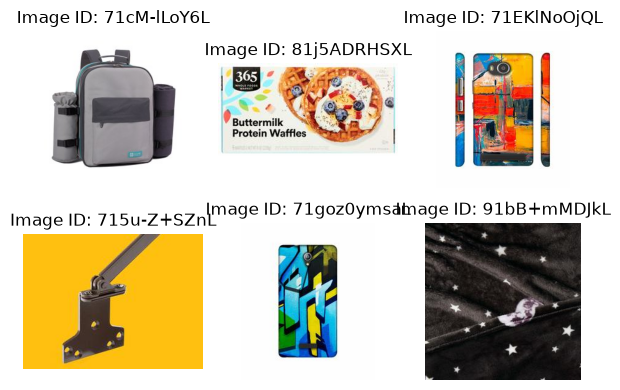

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

# Select a few sample images
sample_images = unique_images_df.sample(6, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(6, 4))

for ax, (_, row) in zip(axes.flat, sample_images.iterrows()):
    image_path = IMAGE_DIR / row["path"]

    img = Image.open(image_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(f"Image ID: {row['image_id']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
missing_files = sum(
    not (IMAGE_DIR / path).is_file()
    for path in unique_images_df["path"]
)

print("Missing image files:", missing_files)

Missing image files: 0


In [1]:
from pathlib import Path
import pandas as pd

# Dataset location
DATASET_DIR = Path(r"D:\PixoAnalytics\Image Retrieval Project")
IMAGE_DIR = DATASET_DIR / "images" / "small"

# Saved artifacts
ARTIFACT_DIR = Path(r"D:\PixoAnalytics\Image Retrieval Artifacts")

# Load prepared data
catalogue_df = pd.read_parquet(ARTIFACT_DIR / "catalogue.parquet")
products_df = pd.read_parquet(ARTIFACT_DIR / "products.parquet")
image_df = pd.read_parquet(ARTIFACT_DIR / "images.parquet")

print("Catalogue:", catalogue_df.shape)
print("Products:", products_df.shape)
print("Images:", image_df.shape)

print("\nCatalogue columns:")
print(catalogue_df.columns.tolist())

# Keep only the information required for image embedding extraction
unique_images_df = (
    catalogue_df[["image_id", "path"]]
    .drop_duplicates(subset="image_id")
    .reset_index(drop=True)
)

print("Unique images to process:", len(unique_images_df))

Catalogue: (734783, 15)
Products: (145615, 8)
Images: (398212, 4)

Catalogue columns:
['product_id', 'image_id', 'image_role', 'height', 'width', 'path', '_merge', 'title', 'brand', 'product_type', 'color', 'style', 'country', 'domain_name', 'full_path']
Unique images to process: 398170


In [2]:
import torch
import torchvision
import open_clip

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.5.1
Torchvision: 0.20.1
CUDA available: True
PyTorch CUDA: 12.1
GPU: NVIDIA GeForce GTX 1050 Ti
GPU memory: 4.0 GB


In [3]:
import torch
import open_clip
import time
from PIL import Image
from pathlib import Path

# Select GPU
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load pretrained CLIP ViT-B/32
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    device=device
)

model.eval()

print("Model loaded successfully!")
print("Device:", device)

c:\Users\muham\anaconda3\envs\image_retrieval\Lib\site-packages\open_clip\factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Model loaded successfully!
Device: cuda


In [4]:
import torch
import time

# Select 8 images
test_df = unique_images_df.head(8)

# Load and preprocess images
image_tensors = []

for _, row in test_df.iterrows():
    image_path = IMAGE_DIR / row["path"]

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        image_tensors.append(preprocess(img))

# Create batch
batch = torch.stack(image_tensors).to(device)

# Run inference
torch.cuda.reset_peak_memory_stats()

start_time = time.time()

with torch.inference_mode():
    embeddings = model.encode_image(batch)
    embeddings = embeddings / embeddings.norm(dim=-1, keepdim=True)

torch.cuda.synchronize()
elapsed = time.time() - start_time

# Move results to CPU
embeddings = embeddings.cpu().numpy()

print("Embedding shape:", embeddings.shape)
print("Processing time:", round(elapsed, 3), "seconds")
print("Peak GPU memory:", round(
    torch.cuda.max_memory_allocated() / 1024**3, 2
), "GB")

Embedding shape: (8, 512)
Processing time: 11.88 seconds
Peak GPU memory: 0.59 GB


In [5]:
import numpy as np

print("Data type:", embeddings.dtype)
print("First embedding (first 10 values):", embeddings[0][:10])

# Check that embeddings are normalized
norms = np.linalg.norm(embeddings, axis=1)
print("Embedding norms:", norms)

assert embeddings.shape == (8, 512)
assert np.allclose(norms, 1.0, atol=1e-5)

print("All checks passed!")

Data type: float32
First embedding (first 10 values): [-0.02391934 -0.03616407  0.04001264 -0.00109551 -0.02098589  0.02175373
 -0.00714725  0.02673591  0.04160543  0.00645345]
Embedding norms: [0.99999994 1.         0.9999999  1.         1.         0.99999994
 1.         1.        ]
All checks passed!


In [6]:
import numpy as np
import json
import time
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import torch

EMBEDDING_DIR = ARTIFACT_DIR / "embeddings"
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)

EMBEDDINGS_PATH = EMBEDDING_DIR / "embeddings.npy"
IMAGE_IDS_PATH = EMBEDDING_DIR / "image_ids.npy"
PROGRESS_PATH = EMBEDDING_DIR / "progress.json"
FAILED_PATH = EMBEDDING_DIR / "failed_images.jsonl"

BATCH_SIZE = 16
CHECKPOINT_INTERVAL = 50  # Save progress every 100 batches

# Ensure a stable ordering
unique_images_df = (
    unique_images_df
    .reset_index(drop=True)
    .copy()
)

TOTAL_IMAGES = len(unique_images_df)
EMBEDDING_DIM = 512

print("Images:", TOTAL_IMAGES)
print("Batch size:", BATCH_SIZE)
print("Expected embedding storage:",
      round(TOTAL_IMAGES * EMBEDDING_DIM * 4 / 1024**3, 2), "GB")

Images: 398170
Batch size: 16
Expected embedding storage: 0.76 GB


In [7]:
def extract_embeddings():

    # Save image IDs in exactly the same order as the embedding rows
    current_ids = unique_images_df["image_id"].astype(str).to_numpy()

    if IMAGE_IDS_PATH.exists():
        saved_ids = np.load(IMAGE_IDS_PATH, allow_pickle=False)

        if not np.array_equal(saved_ids, current_ids):
            raise ValueError(
                "Saved image IDs do not match the current catalogue order. "
                "Use a new output directory or investigate before continuing."
            )
    else:
        np.save(IMAGE_IDS_PATH, current_ids)

    # Load or initialize embedding storage
    if EMBEDDINGS_PATH.exists():
        embeddings_map = np.lib.format.open_memmap(
            EMBEDDINGS_PATH, mode="r+"
        )

        if embeddings_map.shape != (TOTAL_IMAGES, EMBEDDING_DIM):
            raise ValueError("Existing embedding file has an unexpected shape.")

    else:
        embeddings_map = np.lib.format.open_memmap(
            EMBEDDINGS_PATH,
            mode="w+",
            dtype=np.float32,
            shape=(TOTAL_IMAGES, EMBEDDING_DIM)
        )
        embeddings_map[:] = 0

    # Read checkpoint
    if PROGRESS_PATH.exists():
        with open(PROGRESS_PATH, "r") as f:
            progress = json.load(f)

        if progress["total_images"] != TOTAL_IMAGES:
            raise ValueError("Checkpoint belongs to a different catalogue.")

        start_idx = progress["completed_images"]

    else:
        start_idx = 0

    print(f"Resuming from image {start_idx:,} / {TOTAL_IMAGES:,}")

    model.eval()
    model.to(device)

    batch_count = 0
    failed_records = []
    start_time = time.time()

    progress_bar = tqdm(
        range(start_idx, TOTAL_IMAGES, BATCH_SIZE),
        desc="Extracting CLIP embeddings"
    )

    for batch_start in progress_bar:

        batch_end = min(batch_start + BATCH_SIZE, TOTAL_IMAGES)

        tensors = []
        valid_positions = []

        # Load and preprocess images
        for idx in range(batch_start, batch_end):

            row = unique_images_df.iloc[idx]
            image_path = IMAGE_DIR / row["path"]

            try:
                with Image.open(image_path) as img:
                    img = img.convert("RGB")
                    tensor = preprocess(img)

                tensors.append(tensor)
                valid_positions.append(idx - batch_start)

            except Exception as e:
                failed_records.append({
                    "index": int(idx),
                    "image_id": str(row["image_id"]),
                    "path": str(row["path"]),
                    "error": str(e)
                })

        # Encode valid images
        if tensors:

            batch = torch.stack(tensors).to(device)

            with torch.inference_mode():
                batch_embeddings = model.encode_image(batch)

                batch_embeddings = (
                    batch_embeddings /
                    batch_embeddings.norm(dim=-1, keepdim=True)
                )

            batch_embeddings = batch_embeddings.cpu().numpy()

            # Store embeddings at their original positions
            for j, position in enumerate(valid_positions):
                embeddings_map[batch_start + position] = batch_embeddings[j]

            del batch, batch_embeddings

        batch_count += 1
        completed = batch_end

        # Periodic checkpoint
        if batch_count % CHECKPOINT_INTERVAL == 0 or completed == TOTAL_IMAGES:

            embeddings_map.flush()

            if failed_records:
                with open(FAILED_PATH, "a", encoding="utf-8") as f:
                    for record in failed_records:
                        f.write(json.dumps(record) + "\n")

                failed_records.clear()

            progress = {
                "completed_images": completed,
                "total_images": TOTAL_IMAGES,
                "embedding_dim": EMBEDDING_DIM,
                "batch_size": BATCH_SIZE
            }

            with open(PROGRESS_PATH, "w") as f:
                json.dump(progress, f, indent=4)

            elapsed = time.time() - start_time
            progress_bar.set_postfix({
                "completed": f"{completed:,}",
                "elapsed_min": round(elapsed / 60, 1)
            })

    embeddings_map.flush()

    total_time = time.time() - start_time

    print("\nExtraction complete!")
    print("Images processed:", TOTAL_IMAGES)
    print("Total time:", round(total_time / 60, 2), "minutes")
    print("Failed images:", FAILED_PATH.exists())

    del embeddings_map

In [8]:
# Load the existing file (it was generated by your own script)
saved_ids = np.load(
    IMAGE_IDS_PATH,
    allow_pickle=True
)

print("Original dtype:", saved_ids.dtype)
print("Number of IDs:", len(saved_ids))

# Convert to safe Unicode strings
saved_ids = saved_ids.astype(str)

# Overwrite with a non-object array
np.save(IMAGE_IDS_PATH, saved_ids)

# Verify
verified_ids = np.load(
    IMAGE_IDS_PATH,
    allow_pickle=False
)

print("New dtype:", verified_ids.dtype)
print("Number of IDs:", len(verified_ids))

Original dtype: <U11
Number of IDs: 398170
New dtype: <U11
Number of IDs: 398170


In [9]:
current_ids = (
    unique_images_df["image_id"]
    .astype(str)
    .to_numpy(dtype=str)
)

assert np.array_equal(verified_ids, current_ids)

print("Image ID alignment verified!")

Image ID alignment verified!


In [10]:
extract_embeddings()

Resuming from image 24,000 / 398,170


Extracting CLIP embeddings:   0%|          | 0/23386 [00:00<?, ?it/s]


Extraction complete!
Images processed: 398170
Total time: 539.78 minutes
Failed images: False


In [11]:
import numpy as np
import json
from pathlib import Path

EMBEDDING_DIR = Path(
    r"D:\PixoAnalytics\Image Retrieval Artifacts\embeddings"
)

EMBEDDINGS_PATH = EMBEDDING_DIR / "embeddings.npy"
IMAGE_IDS_PATH = EMBEDDING_DIR / "image_ids.npy"
PROGRESS_PATH = EMBEDDING_DIR / "progress.json"
FAILED_PATH = EMBEDDING_DIR / "failed_images.jsonl"

# Load metadata and arrays without loading the entire embedding matrix into RAM
with open(PROGRESS_PATH, "r") as f:
    progress = json.load(f)

embeddings = np.load(EMBEDDINGS_PATH, mmap_mode="r")
image_ids = np.load(IMAGE_IDS_PATH, allow_pickle=False)

print("Extraction progress:", progress)
print("Embedding shape:", embeddings.shape)
print("Image IDs shape:", image_ids.shape)
print("Embedding dtype:", embeddings.dtype)
print("Embedding file size:",
      round(EMBEDDINGS_PATH.stat().st_size / 1024**3, 2), "GB")

print(
    "Completed:",
    progress["completed_images"],
    "/",
    progress["total_images"]
)

# Check failed images
if FAILED_PATH.exists():
    with open(FAILED_PATH, "r", encoding="utf-8") as f:
        failed_count = sum(1 for _ in f)
else:
    failed_count = 0

print("Failed images:", failed_count)

# Verify basic integrity
assert embeddings.shape == (398170, 512)
assert len(image_ids) == 398170
assert progress["completed_images"] == progress["total_images"]
assert embeddings.dtype == np.float32

print("\nBasic integrity checks passed!")

Extraction progress: {'completed_images': 398170, 'total_images': 398170, 'embedding_dim': 512, 'batch_size': 16}
Embedding shape: (398170, 512)
Image IDs shape: (398170,)
Embedding dtype: float32
Embedding file size: 0.76 GB
Completed: 398170 / 398170
Failed images: 0

Basic integrity checks passed!


In [12]:
# Check a sample of embeddings
sample = np.asarray(embeddings[[0, 100, 1000, 10000, 398169]])

norms = np.linalg.norm(sample, axis=1)

print("Sample embedding norms:", norms)

assert np.allclose(norms, 1.0, atol=1e-4)

print("Embedding validation passed!")

Sample embedding norms: [0.99999994 1.         1.         0.99999994 0.99999994]
Embedding validation passed!


In [13]:
import json
import torch
import open_clip
from datetime import datetime, timezone

manifest = {
    "dataset": "Amazon Berkeley Objects (ABO)",
    "unique_images": 398170,
    "embedding_model": "OpenAI CLIP ViT-B/32",
    "pretrained_weights": "openai",
    "embedding_dimension": 512,
    "embedding_dtype": "float32",
    "normalized": True,
    "similarity_metric": "cosine_similarity",
    "extraction_device": torch.cuda.get_device_name(0),
    "pytorch_version": torch.__version__,
    "open_clip_version": open_clip.__version__,
    "batch_size": 16,
    "extraction_time_minutes": 540,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "embedding_file": "embeddings.npy",
    "image_ids_file": "image_ids.npy"
}

with open(EMBEDDING_DIR / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=4)

print("Manifest saved!")

Manifest saved!


In [14]:
# Keep the information needed to display retrieved products
product_image_map = (
    catalogue_df[
        [
            "image_id",
            "product_id",
            "path",
            "title",
            "brand",
            "product_type",
            "color",
            "style"
        ]
    ]
    .drop_duplicates(subset=["image_id", "product_id"])
    .reset_index(drop=True)
)

print("Product-image mappings:", len(product_image_map))
print("Unique products:", product_image_map["product_id"].nunique())
print(product_image_map.head())

Product-image mappings: 703006
Unique products: 145454
      image_id  product_id             path  \
0  81iZlv3bjpL  B06X9STHNG  8c/8ccb5859.jpg   
1  91mIRxgziUL  B06X9STHNG  13/13741743.jpg   
2  91eqBkW06wL  B06X9STHNG  30/3062eff1.jpg   
3  A1BHZSKNbkL  B06X9STHNG  8c/8cf58314.jpg   
4  619y9YG9cnL  B07P8ML82R  9f/9f76d27b.jpg   

                                               title         brand  \
0  Amazon-merk - vinden. Dames Leder Gesloten Tee...         find.   
1  Amazon-merk - vinden. Dames Leder Gesloten Tee...         find.   
2  Amazon-merk - vinden. Dames Leder Gesloten Tee...         find.   
3  Amazon-merk - vinden. Dames Leder Gesloten Tee...         find.   
4  22" Bottom Mount Drawer Slides, White Powder C...  AmazonBasics   

  product_type                    color                 style  
0        SHOES  Veelkleurig Vrouw Blauw  Gesloten-teen pompen  
1        SHOES  Veelkleurig Vrouw Blauw  Gesloten-teen pompen  
2        SHOES  Veelkleurig Vrouw Blauw  Gesloten

In [15]:
import torch
import open_clip
import numpy as np
import pandas as pd

device = "cuda" if torch.cuda.is_available() else "cpu"

model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    device=device
)

model.eval()

print("CLIP loaded on:", device)

c:\Users\muham\anaconda3\envs\image_retrieval\Lib\site-packages\open_clip\factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP loaded on: cuda


In [16]:
from PIL import Image

def retrieve_products(
    query_image,
    top_k=10,
    candidate_k=100
):
    """
    Retrieve visually similar ABO products for a query image.

    Parameters
    ----------
    query_image : PIL.Image or str or Path
        Query image or its file path.
    top_k : int
        Number of unique products to return.
    candidate_k : int
        Number of nearest catalogue images to retrieve initially.
    """

    # Load query image
    if isinstance(query_image, (str, Path)):
        with Image.open(query_image) as img:
            query = preprocess(img.convert("RGB"))
    else:
        query = preprocess(query_image.convert("RGB"))

    # Generate query embedding
    query = query.unsqueeze(0).to(device)

    with torch.inference_mode():
        query_embedding = model.encode_image(query)

        query_embedding = (
            query_embedding /
            query_embedding.norm(dim=-1, keepdim=True)
        )

    query_embedding = np.ascontiguousarray(
        query_embedding.cpu().numpy().astype(np.float32)
    )

    # Search FAISS
    candidate_k = min(candidate_k, index.ntotal)

    scores, faiss_positions = index.search(
        query_embedding,
        candidate_k
    )

    # Map FAISS positions to original embedding positions
    original_positions = valid_positions[faiss_positions[0]]

    matched_image_ids = image_ids[original_positions]

    # Construct image-level result dataframe
    matches_df = pd.DataFrame({
        "image_id": matched_image_ids,
        "similarity": scores[0]
    })

    # Map images to products
    results = matches_df.merge(
        product_image_map,
        on="image_id",
        how="inner"
    )

    # Keep the highest-scoring image for each product
    results = (
        results
        .sort_values("similarity", ascending=False)
        .drop_duplicates(subset="product_id")
        .head(top_k)
        .reset_index(drop=True)
    )

    return results[
        [
            "product_id",
            "image_id",
            "title",
            "brand",
            "product_type",
            "color",
            "style",
            "path",
            "similarity"
        ]
    ]

In [18]:
import faiss
import numpy as np
from pathlib import Path

ARTIFACT_DIR = Path(r"D:\PixoAnalytics\Image Retrieval Artifacts")
EMBEDDING_DIR = ARTIFACT_DIR / "embeddings"

# Load saved FAISS index
INDEX_PATH = EMBEDDING_DIR / "faiss_index.bin"

index = faiss.read_index(str(INDEX_PATH))

# Reload embedding-to-image mapping
valid_positions = np.load(
    EMBEDDING_DIR / "valid_positions.npy",
    allow_pickle=False
)

image_ids = np.load(
    EMBEDDING_DIR / "image_ids.npy",
    allow_pickle=False
)

print("FAISS index loaded!")
print("Indexed vectors:", index.ntotal)
print("Dimensions:", index.d)
print("Valid positions:", len(valid_positions))
print("Image IDs:", len(image_ids))

FAISS index loaded!
Indexed vectors: 398170
Dimensions: 512
Valid positions: 398170
Image IDs: 398170


Query image ID: 41oZuGA050L
Query path: D:\PixoAnalytics\Image Retrieval Project\images\small\d4\d4b67037.jpg


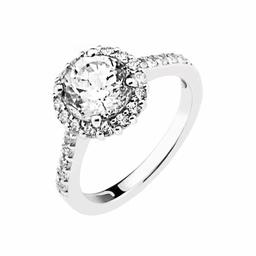

,product_id,image_id,title,brand,product_type,color,style,path,similarity
0,B07HCQRVPP,41oZuGA050L,[アマゾンコレクション] Amazon Collection プラチナメッキスターリングシル...,Amazon Collection(アマゾンコレクション),FINERING,NaN,NaN,d4/d4b67037.jpg,1.000000
1,B07HCY2HQZ,51zXSrGI6PL,[Amazon Collection] Amazon Collection 铂金镀白银 透明...,Amazon Collection(アマゾンコレクション),FINERING,NaN,NaN,5a/5a305f70.jpg,0.969364
2,B07HFVNTYX,51zXSrGI6PL,[Amazon Collection] Amazon Collection 镀铑纯银 透明圆...,Amazon Collection(アマゾンコレクション),RING,NaN,リング,5a/5a305f70.jpg,0.969364
3,B07HCY2BGS,51zXSrGI6PL,[Amazon Collection] Amazon Collection 14K黄金透明圆...,Amazon Collection(アマゾンコレクション),FINERING,NaN,NaN,5a/5a305f70.jpg,0.969364
4,B07HCXK9H9,51zXSrGI6PL,[Amazon Collection] Amazon Collection 铂金镀白银 透明...,Amazon Collection(アマゾンコレクション),FINERING,NaN,NaN,5a/5a305f70.jpg,0.969364
5,B07HCQRQ6S,51zXSrGI6PL,[Amazon Collection] Amazon Collection 镀铑纯银 透明圆...,Amazon Collection(アマゾンコレクション),FINERING,NaN,NaN,5a/5a305f70.jpg,0.969364
6,B07HCSFGSM,51C-LktTcCL,[Amazon Collection] Amazon Collection 镀铑纯银 透明圆...,Amazon Collection(アマゾンコレクション),FINERING,NaN,NaN,e3/e3aa8f8c.jpg,0.968481
7,B07HCY4SS8,51C-LktTcCL,[Amazon Collection] Amazon Collection 镀铑纯银 透明圆...,Amazon Collection(アマゾンコレクション),FINERING,NaN,NaN,e3/e3aa8f8c.jpg,0.968481
8,B07HFX9DG5,71OkPuiWN6L,[Amazon Collection] Amazon Collection 铂金系列 银色透...,Amazon Collection(アマゾンコレクション),RING,NaN,リング,25/25e77e49.jpg,0.966901
9,B07HFXB172,71OkPuiWN6L,[Amazon Collection] Amazon Collection 铂金系列 银色透...,Amazon Collection(アマゾンコレクション),RING,NaN,リング,25/25e77e49.jpg,0.966901


In [19]:
# Pick a sample catalogue image
sample = unique_images_df.sample(1, random_state=123).iloc[0]

query_path = IMAGE_DIR / sample["path"]

print("Query image ID:", sample["image_id"])
print("Query path:", query_path)

# Display query image
from IPython.display import display

display(Image.open(query_path).convert("RGB"))

# Retrieve similar products
results = retrieve_products(
    query_image=query_path,
    top_k=10,
    candidate_k=100
)

display(results)

C:\Users\muham\AppData\Local\Temp\ipykernel_25532\1822936872.py:23: UserWarning: Glyph 12450 (\N{KATAKANA LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\muham\AppData\Local\Temp\ipykernel_25532\1822936872.py:23: UserWarning: Glyph 12510 (\N{KATAKANA LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\muham\AppData\Local\Temp\ipykernel_25532\1822936872.py:23: UserWarning: Glyph 12478 (\N{KATAKANA LETTER ZO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\muham\AppData\Local\Temp\ipykernel_25532\1822936872.py:23: UserWarning: Glyph 12531 (\N{KATAKANA LETTER N}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\muham\AppData\Local\Temp\ipykernel_25532\1822936872.py:23: UserWarning: Glyph 12467 (\N{KATAKANA LETTER KO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\muham\AppData\Local\Temp\ipykernel_25532\1822936872.py:23: UserWarning: Glyph 12524 (\N{KATAKANA LETTER RE}) missing from font(s

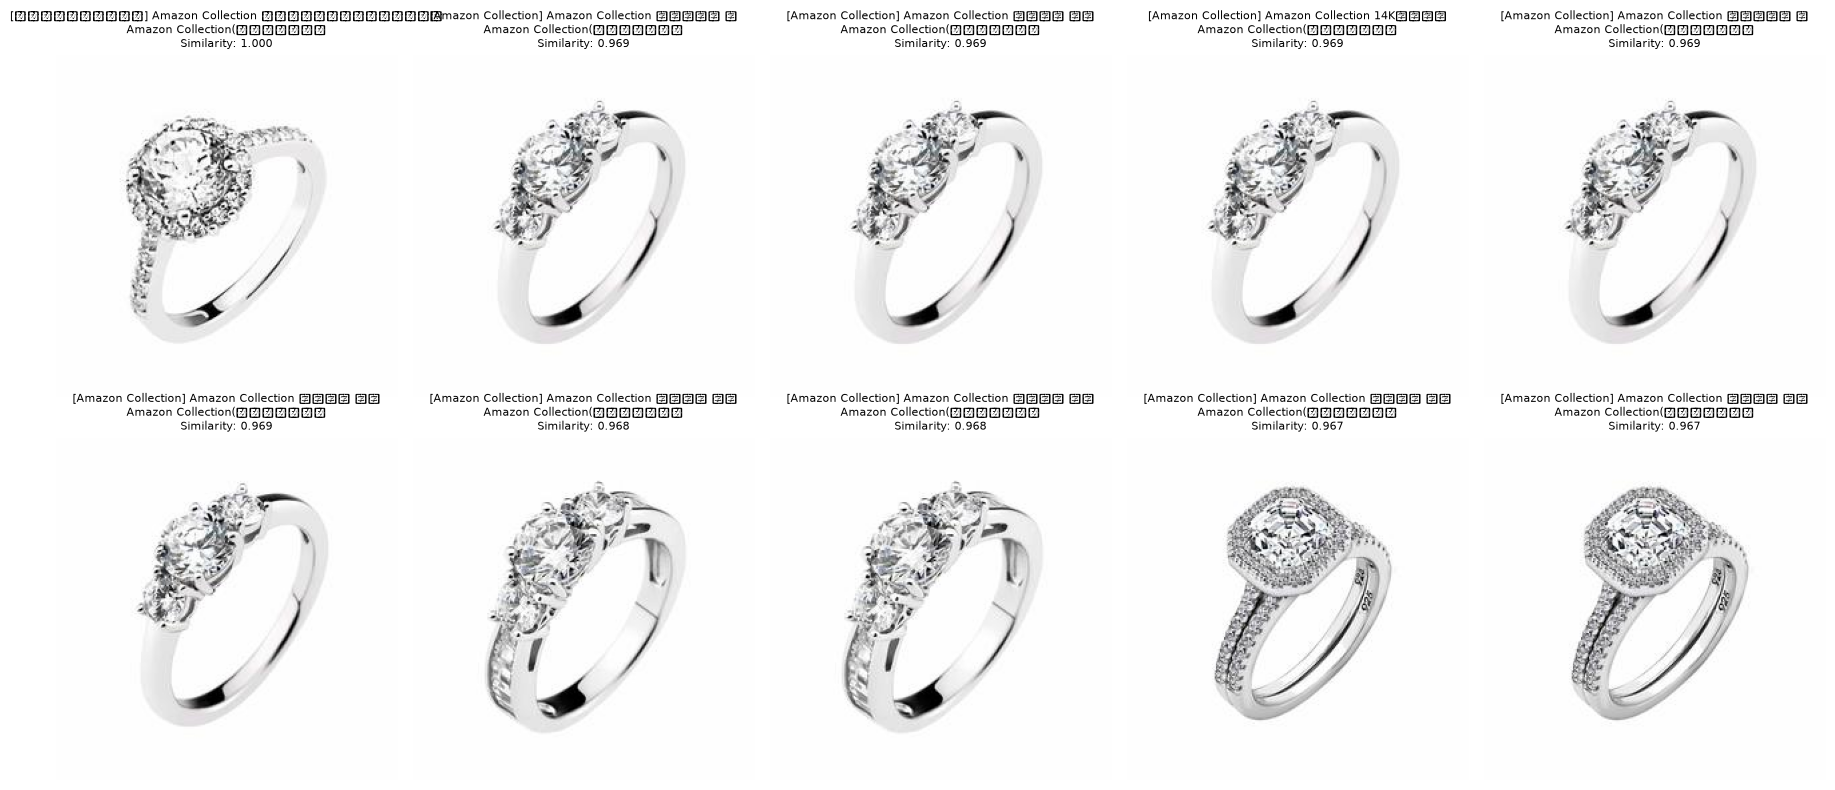

In [20]:
import matplotlib.pyplot as plt
import math

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, results.iterrows()):

    image_path = IMAGE_DIR / row["path"]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    title = str(row["title"])[:45]
    brand = str(row["brand"])[:25]

    ax.set_title(
        f"{title}\n{brand}\nSimilarity: {row['similarity']:.3f}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import pandas as pd
import numpy as np

# One row per unique product-image relationship
eval_catalogue = (
    catalogue_df[["product_id", "image_id", "path"]]
    .drop_duplicates(subset=["product_id", "image_id"])
    .reset_index(drop=True)
)

# Products with at least two different images
image_counts = eval_catalogue.groupby("product_id")["image_id"].nunique()

eligible_products = image_counts[image_counts >= 2].index

eligible_queries = eval_catalogue[
    eval_catalogue["product_id"].isin(eligible_products)
].copy()

# Select one query image per product
eval_queries = (
    eligible_queries
    .groupby("product_id", group_keys=False)
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

# Limit to 500 products for the initial evaluation
eval_queries = eval_queries.sample(
    n=min(500, len(eval_queries)),
    random_state=42
).reset_index(drop=True)

print("Eligible products:", len(eligible_products))
print("Evaluation queries:", len(eval_queries))

Eligible products: 135956
Evaluation queries: 500


In [22]:
from PIL import Image
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import time

def evaluate_query(row, candidate_k=200):

    query_path = IMAGE_DIR / row["path"]

    with Image.open(query_path) as img:
        query_tensor = preprocess(img.convert("RGB"))

    query_tensor = query_tensor.unsqueeze(0).to(device)

    with torch.inference_mode():
        query_embedding = model.encode_image(query_tensor)
        query_embedding = (
            query_embedding /
            query_embedding.norm(dim=-1, keepdim=True)
        )

    query_embedding = np.ascontiguousarray(
        query_embedding.cpu().numpy().astype(np.float32)
    )

    scores, faiss_positions = index.search(
        query_embedding,
        min(candidate_k + 1, index.ntotal)
    )

    original_positions = valid_positions[faiss_positions[0]]

    matches = pd.DataFrame({
        "image_id": image_ids[original_positions],
        "similarity": scores[0]
    })

    # Exclude the query image itself
    matches = matches[
        matches["image_id"] != str(row["image_id"])
    ]

    # Map images to products
    matches = matches.merge(
        product_image_map[["image_id", "product_id"]],
        on="image_id",
        how="inner"
    )

    # Best matching image score per product
    ranked_products = (
        matches.groupby("product_id")["similarity"]
        .max()
        .sort_values(ascending=False)
    )

    return ranked_products.index.astype(str).tolist()

In [23]:
ground_truth = eval_queries["product_id"].astype(str).tolist()

recalls = {1: [], 5: [], 10: []}
reciprocal_ranks = []

start_time = time.time()

for _, row in tqdm(
    eval_queries.iterrows(),
    total=len(eval_queries),
    desc="Evaluating retrieval"
):

    ranked_products = evaluate_query(row)

    true_product = str(row["product_id"])

    # Recall@K: was the correct product in the top K?
    for k in [1, 5, 10]:
        recalls[k].append(
            int(true_product in ranked_products[:k])
        )

    # Reciprocal rank
    if true_product in ranked_products:
        rank = ranked_products.index(true_product) + 1
        reciprocal_ranks.append(1 / rank)
    else:
        reciprocal_ranks.append(0)

elapsed = time.time() - start_time

evaluation_results = {
    "Queries": len(eval_queries),
    "Recall@1": np.mean(recalls[1]),
    "Recall@5": np.mean(recalls[5]),
    "Recall@10": np.mean(recalls[10]),
    "MRR": np.mean(reciprocal_ranks),
    "Evaluation time (seconds)": elapsed
}

display(pd.DataFrame([evaluation_results]).round(4))

Evaluating retrieval:   0%|          | 0/500 [00:00<?, ?it/s]

,Queries,Recall@1,Recall@5,Recall@10,MRR,Evaluation time (seconds)
0,500,0.066,0.174,0.228,0.1183,221.8016


In [24]:
import json

REPORT_DIR = ARTIFACT_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

with open(REPORT_DIR / "evaluation_metrics.json", "w") as f:
    json.dump(evaluation_results, f, indent=4)

print("Evaluation metrics saved.")

Evaluation metrics saved.
